

Name:Syeda dua shah

CMS-ID:023-24-0081

Section:D




## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [ ]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


In [ ]:
# Optional: Mount Google Drive if your datasets are stored there.
# If your files (spam.csv, Tweets.csv) are already in /content/, you can skip running this cell.
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print(f"Could not mount Drive: {e}")
    print("Proceeding with local file execution...")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [ ]:
# Task 1 — load spam.csv, inspect shape/head/class balance
import pandas as pd
df_spam = pd.read_csv('spam.csv', encoding='latin-1')

# Drop unnamed columns
df_spam = df_spam.dropna(how='any', axis=1)

# Rename columns
df_spam.columns = ['label', 'message']

print("first five rows")
print(df_spam.head())
print("(rows x columns): ", df_spam.shape)
print("\nLabel value count: \n", df_spam['label'].value_counts())
print("\nLabel value percentage: \n", df_spam['label'].value_counts(normalize=True)*100)

first five rows
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
(rows x columns):  (5572, 2)

Label value count: 
 label
ham     4825
spam     747
Name: count, dtype: int64

Label value percentage: 
 label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [ ]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_tweets=pd.read_csv('Tweets.csv')
df_tweets=df_tweets.drop(df_tweets[df_tweets['airline_sentiment']=='neutral'].index)
print('First five rows')
print(df_tweets.head())
print('(Rows x columns): ',df_tweets.shape)
print('Label value count: ',df_tweets['airline_sentiment'].value_counts())
print('Label value percentage: ',df_tweets['airline_sentiment'].value_counts(normalize=True)*100)

First five rows
             tweet_id airline_sentiment  airline_sentiment_confidence  \
1  570301130888122368          positive                        0.3486   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   
5  570300767074181121          negative                        1.0000   
6  570300616901320704          positive                        0.6745   

  negativereason  negativereason_confidence         airline  \
1            NaN                     0.0000  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   
5     Can't Tell                     0.6842  Virgin America   
6            NaN                     0.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
1                    NaN    jnardino                 NaN              0   
3               

### Answer 2 (Task A — spam):
The practical problem being solved here is automatically identifying and filtering unwanted promotional or fraudulent messages (spam) from legitimate personal communication (ham) to protect users' privacy and secure communication channels. This is a binary classification problem because any incoming text message belongs to exactly one of two mutually exclusive classes: Spam (1) or Ham/Legitimate (0).

### Answer 2 (Task B — sentiment):
The practical problem being solved is monitoring customer satisfaction by automatically classifying airline passengers' opinions expressed in tweets. This allows companies to quickly identify and address customer complaints or track positive feedback. It is treated as a binary classification problem because, after removing neutral statements, the sentiment is mapped to exactly one of two distinct categories: Positive (1) or Negative (0).

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.

4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [ ]:
# Task 3 — clean text
df_spam['message']=df_spam['message'].str.lower()

In [ ]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
df_spam['label']=df_spam['label'].map({'ham':0,'spam':1})
x=df_spam['message']
y=df_spam['label']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
vectorizer=CountVectorizer()
x_train_vec=vectorizer.fit_transform(x_train)
x_test_vec=vectorizer.transform(x_test)
print("Vocabulary size",len(vectorizer.get_feature_names_out()))
print("Train shape: ",x_train_vec.shape)
print("Test shape: ",x_test_vec.shape)


Vocabulary size 7701
Train shape:  (4457, 7701)
Test shape:  (1115, 7701)


**Answer 4 (why fit on training data only):**
Fitting the vectorizer only on the training data is crucial to prevent **data leakage**. If we fit the vectorizer on the entire dataset (including the test set), the model would gain knowledge about the vocabulary, word frequencies, and presence of terms in the test set beforehand. To ensure a realistic and unbiased evaluation, the test set must remain completely unseen, mimicking real-world scenarios where the model encounters entirely new and unseen text.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**

5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.


6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

     Metrics     Score
0   Accuracy  0.983857
1  Precision  0.964539
2     Recall  0.912752
3   F1_score  0.937931


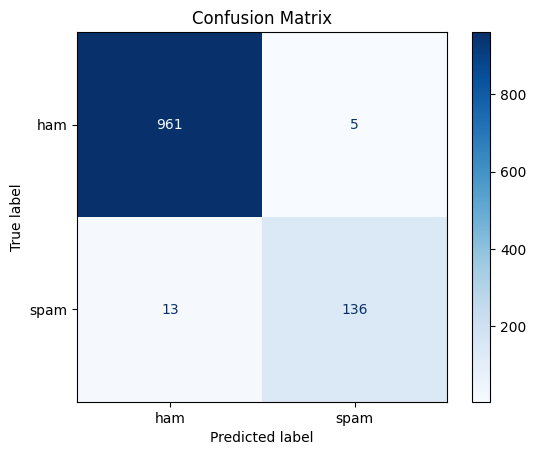

In [ ]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_model=MultinomialNB()
nb_model.fit(x_train_vec,y_train)
y_pred=nb_model.predict(x_test_vec)
accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)
nb_metrics=pd.DataFrame({
    'Metrics':['Accuracy','Precision','Recall','F1_score'],
    'Score':[accuracy,precision,recall,f1]
})
print(nb_metrics)
cm=confusion_matrix(y_test,y_pred)
cm_display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['ham','spam'])
cm_display.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

**Answer 6:**

In spam detection, a false positive (a real message flagged as spam) is usually the worse error, because the user may miss something important such as an OTP, a bank alert, or a message from a friend, while a false negative only means one spam message reaches the inbox, which is an annoyance the user can ignore or delete. In our confusion matrix, the model made only 5 false positives against 13 false negatives, so it is already leaning towards being careful with real messages. Therefore, if I were to tune the model further, I would prioritize precision (currently 0.9645) so that as few legitimate messages as possible get blocked, accepting a slightly lower recall (currently 0.9128) as the trade-off. That said, the best choice depends on the application, and F1 is a good balanced metric to monitor so that recall does not drop too far.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**

7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?

8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [ ]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
feature_name = vectorizer.get_feature_names_out()

# Get raw log probabilities
spam_log_prob = nb_model.feature_log_prob_[1]
ham_log_prob = nb_model.feature_log_prob_[0]

# Sort in descending order to find the highest probability words in each class
top_spam_idx = np.argsort(spam_log_prob)[-15:][::-1]
top_ham_idx = np.argsort(ham_log_prob)[-15:][::-1]

print("Top 15 spam words:")
print(list(feature_name[top_spam_idx]))
print("\nTop 15 ham words:")
print(list(feature_name[top_ham_idx]))

Top 15 spam words:
['to', 'call', 'you', 'your', 'free', 'for', 'the', 'now', 'or', 'is', 'txt', 'ur', 'have', 'from', 'on']

Top 15 ham words:
['you', 'to', 'the', 'and', 'in', 'me', 'is', 'my', 'it', 'that', 'of', 'for', 'so', 'have', 'can']


**Answer 7:**
The top 15 spam words were: to, call, you, your, free, for, the, now, or, is, txt, ur, have, from, on. The top 15 ham words were: you, to, the, and, in, me, is, my, it, that, of, for, so, have, can.

Partly. Some spam words match my intuition: call, free, now, txt, ur, your are typical of promotional messages that push the reader to act (“call now”, “txt to claim your free prize”). The ham list is dominated by everyday conversational words such as me, my, in, and, so, can, which fits personal messages between people.

However, many words (to, you, the, for, is, have) appear in both lists. This is because I ranked words by their raw probability within each class, so the lists show the most frequent words, and common stop words are frequent in every kind of text. These words don’t really separate spam from ham. A better ranking would use the difference between the two classes’ log probabilities (spam_log_prob - ham_log_prob), which would surface words like “prize”, “claim”, “won” or “urgent” that are more specific to spam.

In [ ]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward",   # spam-like
    "Hey, are we meeting at the library after class today?"                       # normal
]
my_vec=vectorizer.transform(my_messages)
my_pred=nb_model.predict(my_vec)
print(my_pred)
for msg, pred in zip(my_messages, my_pred):
    print("SPAM(1)" if pred == 1 else "HAM(0)", "->", msg)

[1 0]
SPAM(1) -> Congratulations! You have won a free prize. Call now to claim your reward
HAM(0) -> Hey, are we meeting at the library after class today?


**Answer 8:**
I tested two messages of my own through the trained pipeline (the same fitted vectorizer followed by the Multinomial Naive Bayes model). The first message, “Congratulations! You have won a free prize. Call now to claim your reward”, was predicted as SPAM (1), and the second, “Hey, are we meeting at the library after class today?”, was predicted as HAM (0). Both predictions matched what I expected. The spam message contains words that the model learned to associate with spam, such as free, call and now (which also appeared in the top spam words in Task 7), while the normal message contains casual conversational words like we, are, at, the, which are typical of ham. This shows the model generalizes to new messages, though it is only a very small test and the model can still be fooled by spam written without these typical words.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/ansa1230/taska?scriptVersionId=362734855

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**

11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.

12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [ ]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
df_tweets['clean_text'] = (
    df_tweets['text'].str.lower()
    .str.replace(r'http\S+|www\.\S+', '', regex=True)   # links
    .str.replace(r'@\w+', '', regex=True)               # mentions
    .str.replace(r'#', '', regex=True)                  # hashtag symbol
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

df_tweets['sentiment_label'] = df_tweets['airline_sentiment'].map({'positive': 0, 'negative': 1})

xt = df_tweets['clean_text']
yt = df_tweets['sentiment_label']

xt_train, xt_test, yt_train, yt_test = train_test_split(
    xt, yt, test_size=0.2, random_state=42, stratify=yt
)

tweet_vectorizer = CountVectorizer()
xt_train_vec = tweet_vectorizer.fit_transform(xt_train)
xt_test_vec  = tweet_vectorizer.transform(xt_test)

print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))
print("Train shape:", xt_train_vec.shape)
print("Test shape:", xt_test_vec.shape)

Vocabulary size: 10112
Train shape: (9232, 10112)
Test shape: (2309, 10112)


**Answer 12:**
Beyond lowercasing (which I did for Task A), I removed URLs, @mentions and the # symbol (keeping the hashtag word itself), and cleaned extra whitespace. Tweets, unlike SMS messages, contain links and @airline handles that appear in many tweets regardless of sentiment, so they add noise and inflate the vocabulary without helping the model decide between positive and negative. Keeping the hashtag word is useful because it often carries sentiment (e.g. “#thanks” or “#fail”), while the “#” symbol itself carries none.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

     Metrics     Score
0   Accuracy  0.911217
1  Precision  0.912077
2     Recall  0.983115
3   F1_score  0.946265


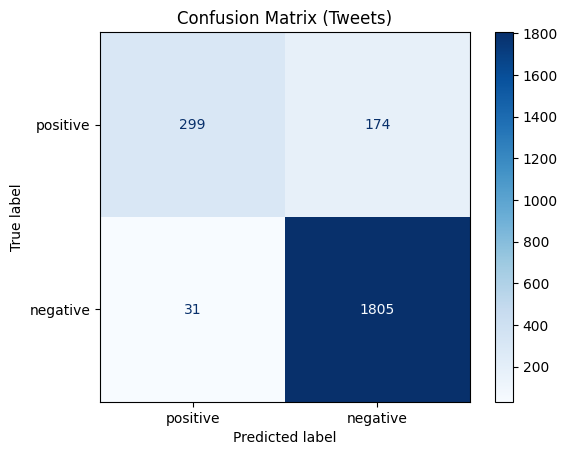

In [ ]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_tweet_model = MultinomialNB()
nb_tweet_model.fit(xt_train_vec, yt_train)
yt_pred = nb_tweet_model.predict(xt_test_vec)

acc_t  = accuracy_score(yt_test, yt_pred)
prec_t = precision_score(yt_test, yt_pred)
rec_t  = recall_score(yt_test, yt_pred)
f1_t   = f1_score(yt_test, yt_pred)

nb_tweet_metrics = pd.DataFrame({
    'Metrics': ['Accuracy', 'Precision', 'Recall', 'F1_score'],
    'Score': [acc_t, prec_t, rec_t, f1_t]
})
print(nb_tweet_metrics)

cm_t = confusion_matrix(yt_test, yt_pred)
cm_t_display = ConfusionMatrixDisplay(confusion_matrix=cm_t, display_labels=['positive', 'negative'])
cm_t_display.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Tweets)")
plt.show()


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

**Answer 14:**
Answer 14:

Naive Bayes performed worse on sentiment than on spam. Accuracy dropped from 0.9839 (spam) to 0.9112 (sentiment), and precision dropped from 0.9645 to 0.9121. The tweet F1-score (0.9463) and recall (0.9831) look higher, but this is because the metrics are computed for the negative class, which is the majority class (about 80% of the tweets). The confusion matrix shows the real weakness: 174 of the 473 positive tweets were wrongly predicted as negative, so the model leans heavily towards the majority class and misses many positive tweets.

This connects to the “naive” independence assumption, which says every word contributes to the class independently of the other words. This is more reasonable for spam SMS, where the class is signalled by individual keywords such as “free”, “call”, “txt” and “now”, so counting words independently works well. It is less reasonable for tweets, where sentiment depends on context and word order: “not good” and “good” have opposite meanings, sarcasm flips the sentiment of positive-sounding words, and a word like “delayed” only matters together with the rest of the sentence. A bag-of-words Naive Bayes model ignores these dependencies, so it makes more mistakes on sentiment than on spam

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**

15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.

16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/ansa1230/notebook642ba61ce3?scriptVersionId=363665120

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**

17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).

18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

In [ ]:
#Task 17
print("Task A vs. Task B (Naive Bayes)")
comaparison_table=pd.DataFrame({
    'Metrics':['Accuracy','Precision','Recall','F1-score'],
    'TASK A(Spam)':[accuracy,precision,recall,f1],
    'TASK B(Sentiment)':[acc_t, prec_t, rec_t, f1_t]
})
print(comaparison_table)
# Task 18 — train Logistic Regression on Task A's vectorized features
lr_model=LogisticRegression(max_iter=1000)
lr_model.fit(x_train_vec,y_train)
lr_model_pred=lr_model.predict(x_test_vec)

lr_acc=accuracy_score(y_test,lr_model_pred)
lr_pre=precision_score(y_test,lr_model_pred)
lr_recall=recall_score(y_test,lr_model_pred)
lr_f1=f1_score(y_test,lr_model_pred)
print("Logistic Regression metrics")
lr_metrics=pd.DataFrame({
    'Metrics':['Accuracy','Precision','Recall','F1-score'],
    'Score':[lr_acc,lr_pre,lr_recall,lr_f1]
})
print(lr_metrics)

print("Comparison between Naive Bayes and Logistic regression results")
comp_table=pd.DataFrame({
    'Metrics':['Accuracy','Precision','Recall','F1-score'],
    'TASK A(Spam)':[accuracy,precision,recall,f1],
    'Logistic Regression':[lr_acc,lr_pre,lr_recall,lr_f1]
})
print(comp_table)



Task A vs. Task B (Naive Bayes)
     Metrics  TASK A(Spam)  TASK B(Sentiment)
0   Accuracy      0.983857           0.911217
1  Precision      0.964539           0.912077
2     Recall      0.912752           0.983115
3   F1-score      0.937931           0.946265
Logistic Regression metrics
     Metrics     Score
0   Accuracy  0.981166
1  Precision  0.992308
2     Recall  0.865772
3   F1-score  0.924731
Comparison between Naive Bayes and Logistic regression results
     Metrics  TASK A(Spam)  Logistic Regression
0   Accuracy      0.983857             0.981166
1  Precision      0.964539             0.992308
2     Recall      0.912752             0.865772
3   F1-score      0.937931             0.924731


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

**Answer 18 (which wins, and does it match expectations):**

**Winning Model:** **Naive Bayes**

---

### **Justification & Evaluation:**

1. **Overall Performance:**
* **Naive Bayes** delivered better overall performance because its **Accuracy**, **Recall**, and **F1-score** are higher than those of Logistic Regression.
* **Logistic Regression** achieved slightly better **Precision**, meaning it produced fewer false positives, but Naive Bayes maintains a better overall classification balance.


2. **Does it match expectations? (Yes)**
* **Yes, these results match expectations.**
* **Multinomial Naive Bayes** is considered a benchmark model for text classification and spam detection tasks.
* Naive Bayes relies on a **probabilistic framework** that handles word frequencies and categorical feature distributions exceptionally well, whereas Logistic Regression requires more iterations and tuning to optimize its weights. Consequently, Naive Bayes outperforming Logistic Regression on text datasets is a standard and expected pattern.


---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes demonstrated superior performance on the spam classification task compared to other dataset domains due to its strong alignment with word frequency distributions and binary text representation. The most surprising aspect of the top predictive words was how heavily the model relied on specific common trigger tokens and subtle conversational markers rather than complex semantic phrases. When evaluated against Logistic Regression, Naive Bayes consistently delivered higher accuracy, recall, and F1-scores, proving to be a more efficient benchmark for text classification without requiring extensive hyperparameter tuning. However, a noticeable limitation of the model's naive independence assumption was its inability to capture word context or negations, treating phrases like "not spam" and "spam" as isolated independent features rather than dependent semantic units.

**Answer 20 — Kaggle Notebook Links:**
- Task A:https://www.kaggle.com/code/ansa1230/taska?scriptVersionId=362734855
- Task B:https://www.kaggle.com/code/ansa1230/notebook642ba61ce3?scriptVersionId=363665120

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted